In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import classification_report, accuracy_score, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('data/final_melb_housing_data.csv')
df.head()

,Rooms,Type,Price,Method,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Source,Year,Month,Price_Tier
0,0.038481,0.411639,7.300000e+05,-0.442074,0.125824,-0.400221,0.053582,-0.871638,0.577745,-0.080322,-0.064007,1.521326,0.748474,0.449006,-0.394359,1.214823,-0.629720,Real,-0.502113,-0.313968,Low
1,0.038481,-0.763027,1.205000e+06,-0.442074,0.826714,0.792428,0.053582,0.452676,0.577745,-0.033438,-0.007474,-0.116715,0.670731,0.017206,0.276850,-1.802431,1.659012,Real,-0.502113,0.040956,High
2,0.038481,-0.763027,8.450000e+05,-0.442074,-0.501288,-0.723462,0.053582,-0.871638,0.577745,-0.006480,-0.028535,0.079850,0.359758,0.167603,-0.434732,1.214823,0.081955,Real,-0.656517,1.460650,Mid
3,0.038481,-0.763027,1.800000e+06,1.888065,-0.464399,1.182546,0.053582,0.452676,0.577745,-0.096145,0.117492,1.521326,1.059448,0.004427,-0.122974,0.879572,0.647320,Real,-0.502113,-0.313968,High
4,-0.868860,-0.763027,9.577662e+05,-1.218788,0.592414,-0.790340,-0.848186,-0.871638,-0.463327,0.001513,0.098640,0.636784,-0.495419,-1.949186,-2.130096,-0.126179,-0.390260,Synthetic,1.350737,-1.733662,Mid


In [ ]:
X_loc = df[['Lattitude', 'Longtitude']]


kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
df['Location_Cluster'] = kmeans.fit_predict(X_loc)

print("✅ Layer 1 Complete: 'Location_Cluster' feature added.")
df['Location_Cluster'].head()

✅ Layer 1 Complete: 'Location_Cluster' feature added.


0    7
1    8
2    7
3    8
4    3
Name: Location_Cluster, dtype: int32

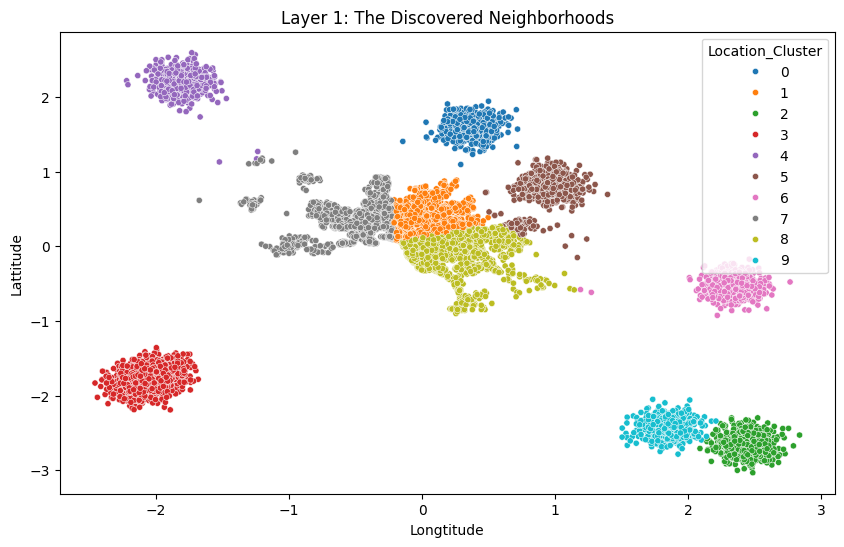

In [ ]:
# 3. Visualize
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Longtitude', y='Lattitude', hue='Location_Cluster', 
                data=df, palette='tab10', s=20)
plt.title("Layer 1: The Discovered Neighborhoods")
plt.show()

In [ ]:
# 1. Define Features (X)
# Drop the answers (Targets) and metadata

X = df.drop(columns=['Price', 'Price_Tier', 'Source'])

y_class = df['Price_Tier']  # Classification target
y_reg = df['Price']         # Regression target

X_train, X_test, y_class_train, y_class_test, y_reg_train, y_reg_test = train_test_split(
  X, y_class, y_reg, test_size=0.2,random_state=42,stratify=y_class
)

print(f"Training Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

Training Data Shape: (14864, 19)
Testing Data Shape: (3716, 19)


In [ ]:
le_tier = LabelEncoder()
le_reg = LabelEncoder()
y_class_train_enc = le_tier.fit_transform(y_class_train)
y_class_test_enc = le_tier.transform(y_class_test)
y_reg_train_enc = le_reg.fit_transform(y_reg_train)
y_reg_test_enc = le_reg.transform(y_reg_test)

clf1 = RandomForestClassifier(n_estimators=100, random_state=42)
clf2 = SVC(probability=True, random_state=42)
clf3 = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)

# 2. The Voting Ensemble
ensemble_clf = VotingClassifier(
    estimators=[('rf', clf1), ('svm', clf2), ('xgb', clf3)],
    voting='soft'
)

# 3. Train & Evaluate
print("Training Classification Ensemble...")
ensemble_clf.fit(X_train, y_class_train_enc)
preds = ensemble_clf.predict(X_test)

print(f"\n✅ Layer 2 Accuracy: {accuracy_score(y_class_test_enc, preds):.2%}")
print("\n--- Classification Report ---")
target_names = le_tier.inverse_transform([0, 1, 2])
print(classification_report(y_class_test_enc, preds, target_names=target_names))

Training Classification Ensemble...


c:\Users\Pooja\Desktop\Devansh\courses\ML\ml\lib\site-packages\xgboost\training.py:199: UserWarning: [13:40:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



✅ Layer 2 Accuracy: 82.97%

--- Classification Report ---
              precision    recall  f1-score   support

        High       0.86      0.86      0.86      1263
         Low       0.88      0.88      0.88      1225
         Mid       0.75      0.75      0.75      1228

    accuracy                           0.83      3716
   macro avg       0.83      0.83      0.83      3716
weighted avg       0.83      0.83      0.83      3716



In [ ]:
# 1. Define Regressor
regressor = XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42)

# 2. Train
print("Training Regression...")
regressor.fit(X_train, y_reg_train)

# 3. Predict & Evaluate
price_preds = regressor.predict(X_test)
mae = mean_absolute_error(y_reg_test, price_preds)
r2 = r2_score(y_reg_test, price_preds)

print(f"\n✅ Layer 3 Results:")
print(f"   Mean Absolute Error: ${mae:,.2f}")
print(f"   R2 Score: {r2:.4f}")

# 4. Compare Actual vs Predicted
comparison = pd.DataFrame({'Actual': y_reg_test, 'Predicted': price_preds})
print("\n--- First 5 Predictions ---")
print(comparison.head())

Training Regression...

✅ Layer 3 Results:
   Mean Absolute Error: $131,958.47
   R2 Score: 0.7820

--- First 5 Predictions ---
             Actual    Predicted
6794   1.700000e+06  2021908.500
16112  1.095697e+06  1143588.375
15094  8.734860e+05   961887.625
9054   1.110000e+06  1126289.250
3722   1.003162e+06  1086482.625



--- 🏆 Top 5 Drivers of House Price ---
    Feature  Importance
0     Rooms    0.179267
5  Bedroom2    0.125522
4  Postcode    0.113343
3  Distance    0.106027
1      Type    0.095343


C:\Users\Pooja\AppData\Local\Temp\ipykernel_22764\337466589.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=fi_df.head(10), palette='viridis')


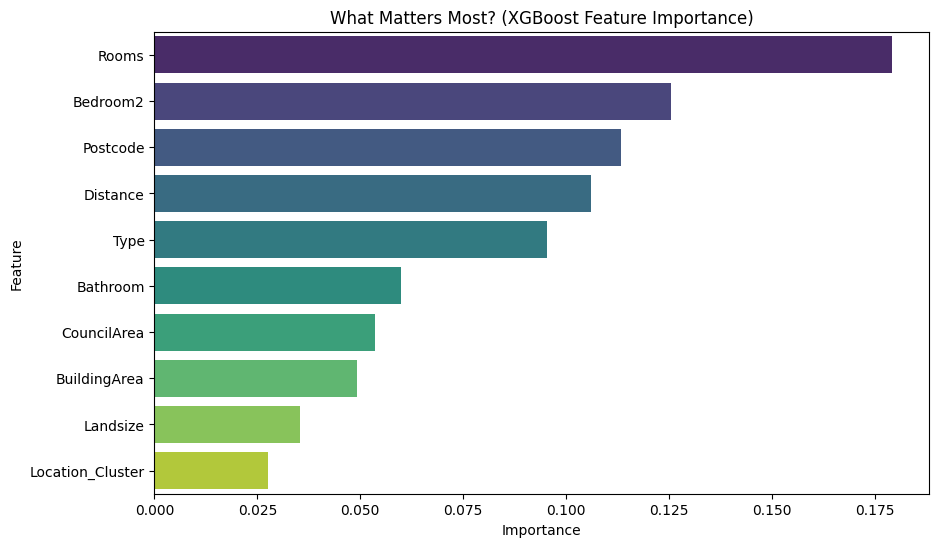

In [ ]:
# 1. Get the Feature Importance from the XGBoost Regressor
# It tracks how many times each feature was used to split a tree.
importance = regressor.feature_importances_
feature_names = X.columns

# 2. Organize into a DataFrame
fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importance})
fi_df = fi_df.sort_values(by='Importance', ascending=False)

print("\n--- 🏆 Top 5 Drivers of House Price ---")
print(fi_df.head(5))

# 3. Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df.head(10), palette='viridis')
plt.title("What Matters Most? (XGBoost Feature Importance)")
plt.show()

In [ ]:
import joblib

brain = {
        'imputer': imputer,
        'scaler': scaler,
        'le_region': le_region,
        'le_tier': le_tier,
        'kmeans': kmeans,
        'classifier': clf,
        'regressor': reg,
        'feature_names': list(X.columns) # Save col names to ensure order matches
    }

joblib.dump(brain, 'titan_brain.pkl')
print("✅ Brain saved to 'titan_brain.pkl'")